# Operating modes: feature engineering for the tree models

`operating_mode_dataset(2).ipynb` built 39 features per vessel-minute and
`model_comparison_lstm.ipynb` put seven classifiers through the same test. Random Forest and
HistGradientBoosting (HGB) read those 39 features one minute at a time, so whatever they know
about *before and after* has to be in the features. This notebook asks which features are
worth adding for them, and which of the 39 should be replaced.

| step | what happens | why |
|---|---|---|
| 1. Labels | episodes and the labeller A vs B ceiling, as before | the same yardstick as the other notebooks |
| 2. Minute grid | the dataset notebook's `to_minutes`, plus per-minute sums of the raw samples | some statistics have to come from the samples, not the minute means |
| 3. Baseline | the 39 features, the dataset notebook's `features()` unchanged | so every difference below is the new features |
| 4. New features | 21 features in 5 families | each aimed at one confusion or one transfer problem |
| 5. Look | one training port call, old and new features side by side | a feature you have not looked at is a feature you do not understand |
| 6. Table | labelled minutes, cleaned, split by episode | same rows as `data/labelled.parquet`, checked |
| 7. Feature sets | baseline, engineered, engineered minus each family | the comparisons below |
| 8. Cross-validation | RF and HGB on every set, 5 folds over the training episodes | where the feature choice is made, never on test |
| 9. Test | baseline against engineered, once | the honest number on the labelled ships |
| 10. Transfer | Calder Trader and Harrowgate against the physics reconstruction | the readme's real question: does it work on ships it never saw? |
| 11. Importance | what the engineered Random Forest relies on | which signals carry the decision now |
| 12. Save | `data/labelled_fe.parquet`, a drop-in for the comparison and grid-search notebooks | |

**What the new features are for**

| family | features | aimed at |
|---|---|---|
| engine runs | engine on in the last half hour, hours since the engine last switched, hours until it next does | manoeuvring vs sea passage, and where in a port call a minute sits. The engine switches cleanly, speed is smoothed across the switch |
| stay context | per engine-off stay: how far the draught moved over the whole stay, how far since arrival and until departure; heading and position spread over the whole stay | in port vs cargo operations (idle before, during a pause, or after cargo work), at anchor vs alongside |
| slow tilt and load | trim and heel spread of 30-minute means; load rate over 6 hours | cargo work tilts the ship over minutes, roll is seconds; slow cargo work |
| position, fixed | position spread computed exactly, floored at GPS noise, capped at 2 ship lengths | the old `pos_spread_*` has a numerical bug (below) |
| raw-sample motion | rudder and speed spread over the raw samples, not the minute means | the same rudder reads differently on the 5 s, 15 s and 60 s loggers |

The last three families **replace** 12 of the 39: `pos_spread_*`, the minute-mean `rudder_std_*`,
`rudder_abs_mean_*`, `sog_std_*`, `trim_std_*` and `heel_std_*`. The resulting **engineered** set
has 48 features.

Run `operating_mode_dataset(2).ipynb` once first (for the check in step 6). Step 10 needs
`testing/data/ground_truth_reconstructed.csv` from `testing/Ground Truth Reconstruction.ipynb`;
without it, step 10 is skipped. The first run takes 10 to 20 minutes, most of it steps 8 and 10.
Their results are cached in `data/feature_engineering/` and reused only while the settings and
the feature definitions (`FEATURE_VERSION`) match, so a second run takes a few minutes;
`SKIP_DONE = False` recomputes everything.

In [1]:
from pathlib import Path

ROOT = Path(".")                 # package folder with labels.csv, vessels.csv, raw/ and data/
DATA = ROOT / "data"
CACHE = DATA / "feature_engineering"     # cross-validation and transfer results are cached here

SPLIT = "time"                   # "time": episodes starting on/after CUTOFF are test
                                 # "vessel": TEST_VESSEL is test, the other labelled vessel is train
CUTOFF = "2025-07-01"
TEST_VESSEL = "wendover-trader"
ON_DISAGREEMENT = "drop"         # both labellers labelled a minute and disagree: "drop", "A" or "B"
MARGIN_MIN = 5                   # training leaves out minutes this close to a label boundary
PAD_DAYS = 3                     # days of context around each labelled stretch (dataset notebook: 2);
                                 # 3 days is the 72 h cap of the run-length features
GAP_HOURS = 6                    # stretches less than this apart are one episode

N_FOLDS = 5
RUN_CV = True                    # step 8: 8 feature sets x 2 models x 5 folds
RUN_TRANSFER = True              # step 10: needs RECONSTRUCTION
SKIP_DONE = True                 # reuse cached results from CACHE when their settings match
RECONSTRUCTION = ROOT / "testing" / "data" / "ground_truth_reconstructed.csv"
TRANSFER_EVERY = 3               # score every 3rd minute of the full vessels; neighbours are near-copies
RANDOM_STATE = 0
N_JOBS = -1                      # CPU cores for the forests, -1 = all

In [2]:
import json
import re
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from matplotlib.colors import LinearSegmentedColormap
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, cohen_kappa_score, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

MODES = ["sea_passage", "manoeuvring", "at_anchor", "in_port", "cargo_operations"]
META = ["vessel", "timestamp", "episode", "label_A", "label_B", "mode", "near_boundary", "split"]

# chart styling, as in the comparison notebook
INK, INK_2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": INK_2, "axes.grid": False, "grid.color": GRID,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 9,
})
BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#104281"])
MODE_COLOUR = {"sea_passage": "#cfe0f7", "manoeuvring": "#f7d2c0", "at_anchor": "#d6e9cf",
               "in_port": "#e4dcf0", "cargo_operations": "#fae3b8"}


def slug(name):
    """'Wendover Trader' -> 'wendover-trader', the folder name under raw/."""
    return re.sub(r"[^a-z0-9]+", "-", str(name).lower()).strip("-")


def macro_f1_present(y_true, y_pred):
    # Macro F1 over the modes that occur in y_true (a fold without an anchorage should not
    # score 0 for at_anchor because there was nothing to find).
    return f1_score(y_true, y_pred, labels=sorted(set(y_true)), average="macro", zero_division=0)

## 1. Labels, episodes and the ceiling

As in the dataset notebook: an episode is a port call or voyage, stretches from either
labeller less than `GAP_HOURS` apart. The ceiling is labeller A against labeller B on the
minutes both labelled.

In [3]:
def load_labels(path, gap_hours=6):
    lab = pd.read_csv(path, parse_dates=["start", "end"])
    # pandas 3 parses at microsecond resolution, the parquet files are in nanoseconds
    lab[["start", "end"]] = lab[["start", "end"]].astype("datetime64[ns]")
    lab["vessel"] = lab["vessel"].map(slug)
    lab["labeller"] = lab["labelled_by"].astype(str).str.split().str[-1]   # 'labeller A' -> 'A'
    if unknown := set(lab["mode"]) - set(MODES):
        raise ValueError(f"unknown modes in labels: {unknown}")
    lab = lab.sort_values(["vessel", "start"]).reset_index(drop=True)
    reach = lab.groupby("vessel")["end"].transform(lambda s: s.cummax().shift())
    new = reach.isna() | (lab["start"] > reach + pd.Timedelta(hours=gap_hours))
    n = new.astype(int).groupby(lab["vessel"]).cumsum()
    lab["episode"] = lab["vessel"] + "-" + n.astype(str).str.zfill(2)
    return lab


def minute_labels(lab, who):
    parts = [pd.DataFrame({"vessel": r.vessel, "mode": r.mode,
                           "timestamp": pd.date_range(r.start, r.end, freq="min", inclusive="left")})
             for r in lab[lab["labeller"] == who].itertuples()]
    return pd.concat(parts, ignore_index=True)


lab = load_labels(ROOT / "labels.csv", GAP_HOURS)
both = minute_labels(lab, "A").merge(minute_labels(lab, "B"), on=["vessel", "timestamp"], suffixes=("_A", "_B"))
a, b = both["mode_A"], both["mode_B"]
print(f"{lab['episode'].nunique()} episodes; {len(both) / 60:.0f} h labelled by both: accuracy {np.mean(a == b):.3f}, "
      f"kappa {cohen_kappa_score(a, b):.3f}, macro F1 {f1_score(a, b, labels=MODES, average='macro'):.3f}")
rater_f1 = pd.Series(f1_score(a, b, labels=MODES, average=None), index=MODES, name="rater agreement")
rater_f1.round(3).to_frame()

23 episodes; 774 h labelled by both: accuracy 0.914, kappa 0.870, macro F1 0.826


,rater agreement
sea_passage,0.999
manoeuvring,0.944
at_anchor,0.557
in_port,0.692
cargo_operations,0.940


## 2. Raw data on a 1-minute grid

`day_blocks`, `read_block` and `to_minutes` are the dataset notebook's, unchanged. One thing is
added: `raw_moments` keeps, per minute, the number of raw samples and their sum, sum of squares
and sum of absolute values for the rudder and the speed over ground. From those, a window's
standard deviation can be taken over the **samples themselves**.

Why that matters: a minute mean averages 12 readings on Calder Trader's 5 s logger, 4 on the
15 s loggers and 1 on Harrowgate's 60 s logger. The standard deviation of minute means therefore
shrinks with the number of samples per minute, and the same rudder movement gives three
different numbers on three ships. The standard deviation of the raw samples does not depend on
how often they were taken.

In [4]:
RAW_COLUMNS = [
    "speed_stw_kn", "speed_sog_kn", "heading_deg", "latitude_gps_deg", "longitude_gps_deg",
    "rudder_angle_deg", "draught_average_m", "trim_deg", "heel_deg",
    "speed_wind_relative_kn", "direction_wind_relative_deg",
    "power_main_engine_total_kw", "speed_main_engine_average_rpm",
    "fuelflow_main_engine_total_kgh",
]
COLUMN_ALIASES = {}     # supplier-Y names -> the names above, if they ever differ

reg = pd.read_csv(ROOT / "vessels.csv")
reg.index = reg["vessel"].map(slug)


def day_blocks(lab_v, pad_days):
    """Days to load around the labelled stretches, grouped into runs of consecutive days."""
    days = set()
    for r in lab_v.itertuples():
        days.update(pd.date_range((r.start - pd.Timedelta(days=pad_days)).normalize(),
                                  (r.end + pd.Timedelta(days=pad_days)).normalize(), freq="D"))
    days = sorted(days)
    blocks = [[days[0]]]
    for d in days[1:]:
        if d - blocks[-1][-1] == pd.Timedelta(days=1):
            blocks[-1].append(d)
        else:
            blocks.append([d])
    return blocks


def read_block(raw_dir, vessel, days):
    files = [raw_dir / vessel / f"{d:%Y-%m-%d}.parquet" for d in days]
    frames = [pd.read_parquet(f) for f in files if f.exists()]
    if not frames:
        return None
    df = pd.concat(frames, ignore_index=True).rename(columns=COLUMN_ALIASES)
    if missing := [c for c in ["timestamp", *RAW_COLUMNS] if c not in df.columns]:
        raise KeyError(f"{vessel}: missing columns {missing}; has {list(df.columns)}. "
                       "Add the supplier's names to COLUMN_ALIASES.")
    ts = (pd.to_datetime(df["timestamp"], utc=True).dt.tz_localize(None)  # naive UTC, like labels.csv
          .astype("datetime64[ns]"))
    df = df.assign(timestamp=ts).set_index("timestamp").sort_index()
    return df.loc[~df.index.duplicated(), RAW_COLUMNS]


def to_minutes(raw):
    """One row per minute, whatever the logging interval. Minutes with no data are NaN."""
    x = raw.astype(float)
    for col, name in [("heading_deg", "heading"), ("direction_wind_relative_deg", "wind_dir")]:
        rad = np.deg2rad(x.pop(col))
        x[f"{name}_sin"], x[f"{name}_cos"] = np.sin(rad), np.cos(rad)
    lon = x["longitude_gps_deg"]
    ok = lon.notna()
    x.loc[ok, "longitude_gps_deg"] = np.rad2deg(np.unwrap(np.deg2rad(lon[ok].to_numpy())))
    m = x.resample("1min").mean()
    m["n_samples"] = raw["speed_sog_kn"].resample("1min").count()
    return m


def raw_moments(raw):
    """Per minute: number of raw samples, their sum, sum of squares and sum of |x|."""
    out = {}
    for col, name in [("rudder_angle_deg", "rudder"), ("speed_sog_kn", "sog")]:
        x = raw[col].astype("float64")
        out[f"{name}_n"] = x.resample("1min").count()
        out[f"{name}_s"] = x.resample("1min").sum()
        out[f"{name}_ss"] = (x * x).resample("1min").sum()
        out[f"{name}_as"] = x.abs().resample("1min").sum()
    return pd.DataFrame(out)

## 3. The baseline: the dataset notebook's 39 features, unchanged

Copied as it is, so the baseline here is exactly the table in `data/labelled.parquet` (step 6
checks that).

In [5]:
FEATURES = [
    "sog_kn", "stw_frac", "stw_minus_sog_kn",
    "sog_mean_15", "sog_std_15", "sog_mean_60", "sog_std_60", "stw_minus_sog_mean_60",
    "power_frac", "rpm_frac", "fuel_frac",
    "power_frac_mean_15", "power_frac_std_15", "power_frac_mean_60", "power_frac_std_60",
    "rudder_abs_deg", "rudder_abs_mean_15", "rudder_std_15", "rudder_abs_mean_60", "rudder_std_60",
    "turn_rate_mean_15", "turn_rate_mean_60", "heading_circstd_60", "heading_circstd_180",
    "pos_spread_60_shiplengths", "pos_spread_180_shiplengths",
    "load_frac", "load_rate_abs_60", "load_rate_abs_180",
    "trim_std_60", "trim_std_180", "heel_std_60", "heel_std_180", "heel_abs_deg",
    "wind_rel_kn", "wind_rel_cos", "wind_rel_cos_mean_60",
    "hours_since_moving", "hours_until_moving",
]


def features(m, reg):
    """m: one vessel's minute grid. reg: its row from vessels.csv."""
    def win(s, w):
        return s.rolling(w, center=True, min_periods=max(1, w // 2))

    f = pd.DataFrame(index=m.index)

    sog, stw = m["speed_sog_kn"], m["speed_stw_kn"]
    f["sog_kn"] = sog
    f["stw_frac"] = stw / reg["design_speed_kn"]
    f["stw_minus_sog_kn"] = stw - sog            # water past a hull that stays put: anchored in a current
    for w in (15, 60):
        f[f"sog_mean_{w}"] = win(sog, w).mean()
        f[f"sog_std_{w}"] = win(sog, w).std()
    f["stw_minus_sog_mean_60"] = win(stw - sog, 60).mean()

    pf = m["power_main_engine_total_kw"] / reg["installed_power_kw"]
    f["power_frac"] = pf
    f["rpm_frac"] = m["speed_main_engine_average_rpm"] / reg["max_shaft_speed_rpm"]
    f["fuel_frac"] = m["fuelflow_main_engine_total_kgh"] / (0.185 * reg["installed_power_kw"])
    for w in (15, 60):
        f[f"power_frac_mean_{w}"] = win(pf, w).mean()
        f[f"power_frac_std_{w}"] = win(pf, w).std()

    rud = m["rudder_angle_deg"]
    f["rudder_abs_deg"] = rud.abs()
    for w in (15, 60):
        f[f"rudder_abs_mean_{w}"] = win(rud.abs(), w).mean()
        f[f"rudder_std_{w}"] = win(rud, w).std()

    hs, hc = m["heading_sin"], m["heading_cos"]
    heading = np.rad2deg(np.arctan2(hs, hc))
    turn = ((heading.diff() + 180) % 360 - 180).abs()          # degrees per minute
    for w in (15, 60):
        f[f"turn_rate_mean_{w}"] = win(turn, w).mean()
    for w in (60, 180):                                          # swinging at anchor vs fixed alongside
        r = np.hypot(win(hs, w).mean(), win(hc, w).mean()).clip(1e-9, 1)
        f[f"heading_circstd_{w}"] = np.rad2deg(np.sqrt(-2 * np.log(r)))

    lat = m["latitude_gps_deg"]
    north = lat * 111_320.0
    east = m["longitude_gps_deg"] * 111_320.0 * np.cos(np.deg2rad(lat))
    for w in (60, 180):                                          # metres of wander, in ship lengths
        spread = np.sqrt(win(north, w).var() + win(east, w).var())
        f[f"pos_spread_{w}_shiplengths"] = spread / reg["length_pp_m"]

    load = ((m["draught_average_m"] - reg["draught_ballast_m"])
            / (reg["draught_laden_m"] - reg["draught_ballast_m"]))
    f["load_frac"] = load                                        # 0 ballast, 1 laden
    smooth = win(load, 15).mean()
    for w in (60, 180):                                          # cargo going in or out, per hour
        half = w // 2
        f[f"load_rate_abs_{w}"] = ((smooth.shift(-half) - smooth.shift(half)) / (w / 60)).abs()

    for col, name in [("trim_deg", "trim"), ("heel_deg", "heel")]:   # std: trim sign convention differs per ship
        for w in (60, 180):
            f[f"{name}_std_{w}"] = win(m[col], w).std()
    f["heel_abs_deg"] = m["heel_deg"].abs()

    f["wind_rel_kn"] = m["speed_wind_relative_kn"]
    f["wind_rel_cos"] = m["wind_dir_cos"]                        # +1 dead ahead: an anchored ship lies head to wind
    f["wind_rel_cos_mean_60"] = win(m["wind_dir_cos"], 60).mean()

    moving = win(sog, 5).mean() > 3.0
    t = pd.Series(f.index, index=f.index)
    f["hours_since_moving"] = ((t - t.where(moving).ffill()).dt.total_seconds() / 3600).clip(upper=72)
    f["hours_until_moving"] = ((t.where(moving).bfill() - t).dt.total_seconds() / 3600).clip(upper=72)

    assert list(f.columns) == FEATURES, set(f.columns) ^ set(FEATURES)
    return f.astype("float32")

## 4. The new features

Five families, each written against a specific weakness found in the other notebooks. The
`testing/Ground Truth Reconstruction.ipynb` notebook was a big help here: it showed that the
engine switches cleanly at a mode change while speed is smoothed across it, that heading and
position separate anchored from alongside over a *whole stay* better than over a window, and
that statistics of minute means differ between the 5 s, 15 s and 60 s loggers.

**Engine runs.** `power_frac > 1 %` is the engine running. For the stretch of equal engine
state each minute sits in: the share of the last half hour with the engine on, the hours since
the engine last switched and the hours until it next does, both capped at 72 h like
`hours_since_moving`. A telemetry gap up to 30 minutes keeps the state; a longer one breaks
the stretch, and the side that touches it becomes unknown (NaN) unless 72 h are visible anyway.
`hours_since_moving` asks the same question with speed above 3 knots, and speed lags the switch.

**Stay context.** An engine-off stretch is a *stay*: at anchor, alongside, or drifting. For each
stay, the draught (as load, 0 = ballast to 1 = laden) at its start and at its end, then per
minute:
- `stay_load_change`: how far the draught moved over the whole stay. Zero for an anchorage or a
  port call without cargo.
- `load_change_since_stay_start`, `load_change_until_stay_end`: how much of it has happened yet.
  Idle before cargo work: since ≈ 0. Idle after: until ≈ 0. A pause in the middle: both clearly
  above 0. The old load rate cannot tell a pause from idle time, because in both the draught
  stands still.
- `stay_heading_circstd`, `stay_pos_spread_shiplengths`: heading and position spread over the
  whole stay, 30 minutes trimmed from each end (the speed smoothing moves the heading there).
  Anchored ships swing tens of degrees over a stay; moored ships do not move at all.

These look at the whole stay, ahead as well as back. Like the centred windows in the dataset
notebook, that suits labelling history offline, not a real-time classifier.

**Slow tilt and load.** `trim_std_*` and `heel_std_*` mix two things: the ship tilting as cargo
goes into one hatch after another (minutes to hours) and rolling (seconds). The new versions
average over 30 minutes first, which keeps the tilt and removes most of the roll. How much roll
is left still depends a little on the logger (more samples, less roll left); 30 minutes is where
that was small and cargo and idle sat furthest apart (see "Tried and not kept" below).
`load_rate_abs_360` adds a 6-hour load rate for slow cargo work.

**Position, fixed.** `pos_spread_*` takes a rolling variance of positions in metres from the
equator, millions of metres. pandas' rolling variance updates a running sum as the window moves
and cannot keep a few square metres at that size: alongside it comes out negative (so `sqrt`
gives NaN) or as noise, and the result depends on how much history was loaded. The fix computes
each window's variance in two passes around the window's own mean. Two more steps make it
transferable: a floor of 0.02 ship lengths (about 5 m), because alongside the fixed value is
just GPS noise, 0.9 m on the 5 s logger and 2.9 m on the 60 s logger; and a cap at 2 ship
lengths, because under way, distance covered divided by ship length only says which ship it is.

**Raw-sample motion.** Rudder and speed spread over the raw samples, using `raw_moments` from
step 2.

In [6]:
HOURS_CAP = 72                    # the cap the dataset notebook uses for hours since / until moving
ENGINE_ON_FRAC = 0.01             # engine running above 1 % of installed power
STATE_GAP_MIN = 30                # a telemetry gap up to this long keeps the engine state
EDGE_MIN = 30                     # minutes trimmed from each end of a stay for its heading/position spread
SPREAD_FLOOR_SHIPLENGTHS = 0.02   # about 5 m on a 252 m ship; GPS noise alongside is 1 to 3 m
SPREAD_CAP_SHIPLENGTHS = 2.0      # above this the ship is under way
SLOW_MIN = 30                     # minutes averaged before the trim / heel spread is taken


def win(s, w):
    return s.rolling(w, center=True, min_periods=max(1, w // 2))


def wsum(s, w):
    return s.rolling(w, center=True, min_periods=1).sum()


def raw_window_std(mom, name, w):
    """Standard deviation of all raw samples in a centred window of w minutes."""
    n, s, ss = wsum(mom[f"{name}_n"], w), wsum(mom[f"{name}_s"], w), wsum(mom[f"{name}_ss"], w)
    var = (ss - s * s / n.where(n > 0)) / (n - 1).where(n > 1)
    return np.sqrt(var.clip(lower=0))


def raw_window_absmean(mom, name, w):
    n, a = wsum(mom[f"{name}_n"], w), wsum(mom[f"{name}_as"], w)
    return a / n.where(n > 0)


def exact_rolling_var(x, w, min_periods, chunk=20_000):
    """Centred rolling variance, two passes per window, so that a few square metres survive
    next to coordinates of millions of metres. Same window convention as pandas' center=True."""
    a = np.asarray(x, dtype="float64")
    left, right = w // 2, w - 1 - w // 2
    view = sliding_window_view(np.concatenate([np.full(left, np.nan), a, np.full(right, np.nan)]), w)
    out = np.full(len(a), np.nan)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)       # all-NaN windows
        for i in range(0, len(a), chunk):
            v = view[i:i + chunk]
            ok = np.sum(~np.isnan(v), axis=1) >= min_periods
            out[i:i + chunk] = np.where(ok, np.nanvar(v, axis=1, ddof=1), np.nan)
    return out


def local_metres(m):
    """North and east in metres from the first position of the block."""
    lat, lon = m["latitude_gps_deg"], m["longitude_gps_deg"]
    i0 = lat.first_valid_index()
    north = (lat - lat[i0]) * 111_320.0
    east = (lon - lon[i0]) * 111_320.0 * np.cos(np.deg2rad(lat))
    return north, east


def circstd_deg(s, c):
    r = np.clip(np.hypot(np.nanmean(s), np.nanmean(c)), 1e-9, 1)
    return np.rad2deg(np.sqrt(-2 * np.log(r)))


def engine_runs(m, reg):
    """Engine state per minute, the stretches ("runs") of equal state, and for every minute the
    hours since its run started and until it ends, capped at HOURS_CAP. NaN where the run reaches
    the edge of the loaded data or a long telemetry gap and less than the cap is visible."""
    pf = m["power_main_engine_total_kw"] / reg["installed_power_kw"]
    on = (pf > ENGINE_ON_FRAC).astype("float64").where(pf.notna()).ffill(limit=STATE_GAP_MIN)
    key = on.fillna(-1).to_numpy()                      # 1 on, 0 off, -1 unknown
    n = len(key)
    first = np.r_[True, key[1:] != key[:-1]]
    rid = np.cumsum(first) - 1                          # run number of every minute
    start = np.flatnonzero(first)
    end = np.r_[start[1:], n]                           # exclusive
    state = key[start]
    runs = pd.DataFrame({
        "start": start, "end": end, "state": state,
        "start_known": (state != -1) & np.r_[False, state[:-1] != -1],
        "end_known": (state != -1) & np.r_[state[1:] != -1, False],
    })
    pos = np.arange(n)
    elapsed, left = (pos - start[rid] + 1) / 60, (end[rid] - pos) / 60
    elapsed = np.where(runs["start_known"].to_numpy()[rid] | (elapsed >= HOURS_CAP),
                       np.minimum(elapsed, HOURS_CAP), np.nan)
    left = np.where(runs["end_known"].to_numpy()[rid] | (left >= HOURS_CAP), np.minimum(left, HOURS_CAP), np.nan)
    unknown = state[rid] == -1
    elapsed[unknown], left[unknown] = np.nan, np.nan
    return on, elapsed, left, runs


def stay_context(m, reg, runs):
    """Per engine-off run (a stay): draught movement over the stay, and heading and position
    spread over its inner part. 0 while the engine runs, NaN where the state is unknown."""
    load = ((m["draught_average_m"] - reg["draught_ballast_m"])
            / (reg["draught_laden_m"] - reg["draught_ballast_m"]))
    load = load.rolling(31, center=True, min_periods=10).median().to_numpy()
    hs, hc = m["heading_sin"].to_numpy(), m["heading_cos"].to_numpy()
    north, east = (x.to_numpy() for x in local_metres(m))
    out = {c: np.zeros(len(m)) for c in NEW_FAMILIES["stay_context"]}
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)       # stays with no position or draught at all
        for r in runs.itertuples():
            a, b = r.start, r.end
            if r.state == -1:
                for col in out.values():
                    col[a:b] = np.nan
                continue
            if r.state == 1:
                continue
            head, tail = load[a:min(b, a + 60)], load[max(a, b - 60):b]
            l0 = np.nanmedian(head) if r.start_known and np.isfinite(head).any() else np.nan
            l1 = np.nanmedian(tail) if r.end_known and np.isfinite(tail).any() else np.nan
            out["stay_load_change"][a:b] = abs(l1 - l0)
            out["load_change_since_stay_start"][a:b] = np.abs(load[a:b] - l0)
            out["load_change_until_stay_end"][a:b] = np.abs(l1 - load[a:b])
            ia, ib = (a + EDGE_MIN, b - EDGE_MIN) if b - a > 3 * EDGE_MIN else (a, b)
            if ib - ia >= 60:
                out["stay_heading_circstd"][a:b] = circstd_deg(hs[ia:ib], hc[ia:ib])
                spread = np.sqrt(np.nanvar(north[ia:ib]) + np.nanvar(east[ia:ib])) / reg["length_pp_m"]
                out["stay_pos_spread_shiplengths"][a:b] = np.clip(spread, SPREAD_FLOOR_SHIPLENGTHS,
                                                                  SPREAD_CAP_SHIPLENGTHS)
            else:
                out["stay_heading_circstd"][a:b] = np.nan
                out["stay_pos_spread_shiplengths"][a:b] = np.nan
    return out

In [7]:
NEW_FAMILIES = {
    "engine_runs": ["engine_on_frac_30", "run_hours_elapsed", "run_hours_left"],
    "stay_context": ["stay_load_change", "load_change_since_stay_start", "load_change_until_stay_end",
                     "stay_heading_circstd", "stay_pos_spread_shiplengths"],
    "slow_tilt_and_load": ["trim_slow_std_60", "trim_slow_std_180", "heel_slow_std_60", "heel_slow_std_180",
                           "load_rate_abs_360"],
    "position_fixed": ["pos_spread_fixed_60_shiplengths", "pos_spread_fixed_180_shiplengths"],
    "raw_sample_motion": ["rudder_std_raw_15", "rudder_std_raw_60", "rudder_abs_mean_raw_15",
                          "rudder_abs_mean_raw_60", "sog_std_raw_15", "sog_std_raw_60"],
}
NEW_FEATURES = [c for cols in NEW_FAMILIES.values() for c in cols]

# Raise FEATURE_VERSION after changing how any feature is computed: cached results from step 8
# and 10 carry it, and are recomputed when it or one of the constants above differs.
FEATURE_VERSION = 1
FEATURE_SETTINGS = {"version": FEATURE_VERSION, "hours_cap": HOURS_CAP, "engine_on_frac": ENGINE_ON_FRAC,
                    "state_gap_min": STATE_GAP_MIN, "edge_min": EDGE_MIN, "slow_min": SLOW_MIN,
                    "spread_floor": SPREAD_FLOOR_SHIPLENGTHS, "spread_cap": SPREAD_CAP_SHIPLENGTHS}

# old feature -> the new one that does its job without the logging-interval effect or the bug
REPLACES = {
    "pos_spread_60_shiplengths": "pos_spread_fixed_60_shiplengths",
    "pos_spread_180_shiplengths": "pos_spread_fixed_180_shiplengths",
    "rudder_std_15": "rudder_std_raw_15", "rudder_std_60": "rudder_std_raw_60",
    "rudder_abs_mean_15": "rudder_abs_mean_raw_15", "rudder_abs_mean_60": "rudder_abs_mean_raw_60",
    "sog_std_15": "sog_std_raw_15", "sog_std_60": "sog_std_raw_60",
    "trim_std_60": "trim_slow_std_60", "trim_std_180": "trim_slow_std_180",
    "heel_std_60": "heel_slow_std_60", "heel_std_180": "heel_slow_std_180",
}
ENGINEERED = [c for c in FEATURES if c not in REPLACES] + NEW_FEATURES


def new_features(m, mom, reg):
    """The 21 new features. m: minute grid, mom: raw_moments of the same block, reg: register row."""
    f = pd.DataFrame(index=m.index)

    # engine runs
    on, elapsed, left, runs = engine_runs(m, reg)
    f["engine_on_frac_30"] = win(on, 30).mean()
    f["run_hours_elapsed"] = elapsed          # hours since the engine last started or stopped
    f["run_hours_left"] = left                # hours until it next does

    # stay context
    for name, values in stay_context(m, reg, runs).items():
        f[name] = values

    # slow tilt and a 6 h load rate
    for col, name in [("trim_deg", "trim"), ("heel_deg", "heel")]:
        slow = m[col].rolling(SLOW_MIN, center=True, min_periods=SLOW_MIN // 2).mean()   # tilt stays, roll goes
        for w in (60, 180):
            f[f"{name}_slow_std_{w}"] = win(slow, w).std()
    load = ((m["draught_average_m"] - reg["draught_ballast_m"])
            / (reg["draught_laden_m"] - reg["draught_ballast_m"]))
    smooth = win(load, 15).mean()
    f["load_rate_abs_360"] = ((smooth.shift(-180) - smooth.shift(180)) / 6).abs()

    # position spread without the rolling-variance bug, floored at GPS noise, capped when under way
    north, east = local_metres(m)
    for w in (60, 180):
        spread = np.sqrt(exact_rolling_var(north, w, w // 2) + exact_rolling_var(east, w, w // 2))
        f[f"pos_spread_fixed_{w}_shiplengths"] = np.clip(spread / reg["length_pp_m"],
                                                         SPREAD_FLOOR_SHIPLENGTHS, SPREAD_CAP_SHIPLENGTHS)

    # rudder and speed spread over the raw samples
    for w in (15, 60):
        f[f"rudder_std_raw_{w}"] = raw_window_std(mom, "rudder", w)
        f[f"rudder_abs_mean_raw_{w}"] = raw_window_absmean(mom, "rudder", w)
        f[f"sog_std_raw_{w}"] = raw_window_std(mom, "sog", w)

    f = f[NEW_FEATURES]
    return f.astype("float32")


def block_features(vessel, days):
    """Minute grid and all 60 features (39 baseline + 21 new) for a run of consecutive days."""
    raw = read_block(ROOT / "raw", vessel, days)
    if raw is None:
        return None, None
    m = to_minutes(raw)
    with warnings.catch_warnings():
        # the baseline pos_spread takes sqrt of a negative variance: the bug described above
        warnings.filterwarnings("ignore", "invalid value encountered in sqrt", RuntimeWarning)
        f = pd.concat([features(m, reg.loc[vessel]), new_features(m, raw_moments(raw), reg.loc[vessel])], axis=1)
    return m, f


print(f"{len(NEW_FEATURES)} new features, {len(REPLACES)} of the 39 replaced, "
      f"{len(ENGINEERED)} in the engineered set")

21 new features, 12 of the 39 replaced, 48 in the engineered set


**Tried and not kept.** Measured while building this notebook (HGB, trained on the training
episodes, scored against the reconstruction as in step 10):

| tried | what happened | so |
|---|---|---|
| total length of the engine run, and the position within it (0 at the start, 1 at the end) | at_anchor F1 fell from 0.98 to 0.72 on Wendover and from 0.98 to 0.85 on Calder | there are only 4 training anchorages, and the trees learned how long *those* lasted. Dropped; hours since and until the switch, capped at 72 h, stay |
| position spread fixed, without the cap | manoeuvring F1 on Harrowgate fell from 0.86 to 0.71 | under way, distance covered divided by ship length tells the model which ship it is. Capped at 2 ship lengths |
| speed as a fraction of design speed, acceleration, change in power | macro F1 on Harrowgate 0.9847 with them, 0.9845 without | minute-to-minute differences depend on the logger as well; not worth four columns |
| raw-sample standard deviation for trim and heel (from the reconstruction notebook) | puts the roll back in and blurs idle against cargo | average first, then take the spread |
| 10-minute means for trim and heel, as in the reconstruction notebook | the 180-minute trim spread at anchor sat 1.9 IQR low on Calder and 4.4 high on Harrowgate (minute means: 4.7 and 10.9; 30-minute means: 1.2 and 2.6). On the labelled ships its median during cargo work was 68 times the idle median (30-minute means: 106 times). Random Forest's in_port F1 on Calder: 0.94 (30-minute means: 0.95) | 30-minute means. 60-minute means shift even less, but are as wide as the 60-minute window they feed |

## 5. Look at them first

One **training** port call, Wendover Trader's second episode (an anchorage, then alongside with
cargo work), with the old and the new version of a feature in the same panel. The background
is labeller A's mode. What to look for:
- the engine (power) switches cleanly where the labels change, speed ramps across the switch;
- `load_change_since_stay_start` rises during cargo work and stays up after it,
  `load_change_until_stay_end` falls to zero at the end of it: idle before and idle after look
  different now;
- the old `pos_spread_60` has holes (NaN) and spikes alongside, the fixed one sits on the floor
  alongside and well above it at anchor;
- the stay-level heading spread is a flat, high value through the whole anchorage.

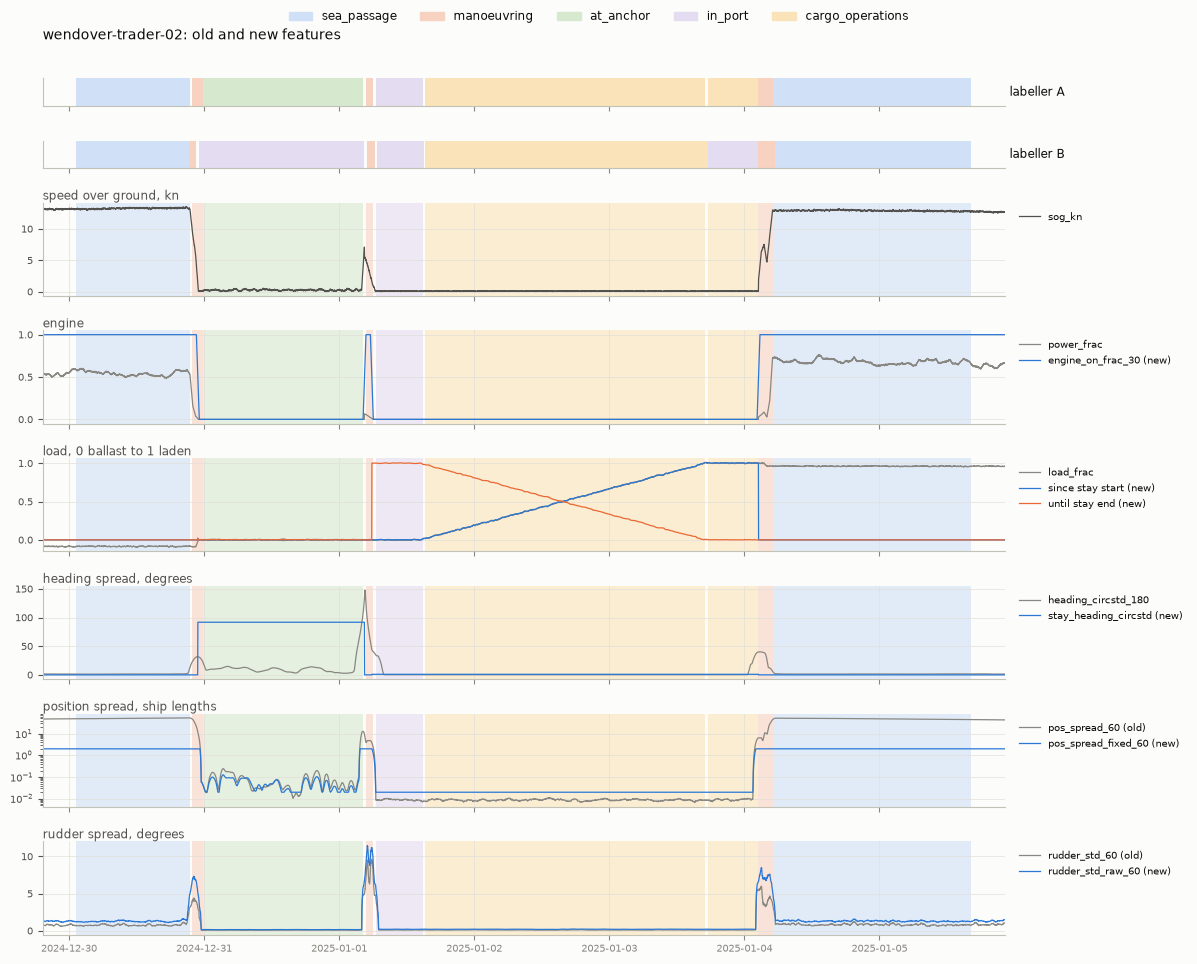

In [8]:
EXAMPLE_EPISODE = "wendover-trader-02"     # a training episode; pick another from lab["episode"]


def plot_features(episode):
    e = lab[lab["episode"] == episode]
    v, start, end = e["vessel"].iloc[0], e["start"].min() - pd.Timedelta(hours=6), e["end"].max() + pd.Timedelta(hours=6)
    days = pd.date_range((start - pd.Timedelta(days=PAD_DAYS)).normalize(),
                         (end + pd.Timedelta(days=PAD_DAYS)).normalize(), freq="D")
    m, f = block_features(v, days)
    f = f.loc[start:end]
    panels = [
        ("speed over ground, kn", [("sog_kn", INK_2, "sog_kn")]),
        ("engine", [("power_frac", MUTED, "power_frac"), ("engine_on_frac_30", BLUE, "engine_on_frac_30 (new)")]),
        ("load, 0 ballast to 1 laden", [("load_frac", MUTED, "load_frac"),
                                        ("load_change_since_stay_start", BLUE, "since stay start (new)"),
                                        ("load_change_until_stay_end", ORANGE, "until stay end (new)")]),
        ("heading spread, degrees", [("heading_circstd_180", MUTED, "heading_circstd_180"),
                                     ("stay_heading_circstd", BLUE, "stay_heading_circstd (new)")]),
        ("position spread, ship lengths", [("pos_spread_60_shiplengths", MUTED, "pos_spread_60 (old)"),
                                           ("pos_spread_fixed_60_shiplengths", BLUE, "pos_spread_fixed_60 (new)")]),
        ("rudder spread, degrees", [("rudder_std_60", MUTED, "rudder_std_60 (old)"),
                                    ("rudder_std_raw_60", BLUE, "rudder_std_raw_60 (new)")]),
    ]
    strips = [w for w in ("A", "B") if (e["labeller"] == w).any()]
    fig, axes = plt.subplots(len(strips) + len(panels), 1, sharex=True,
                             figsize=(13, 0.4 * len(strips) + 1.35 * len(panels) + 0.8),
                             gridspec_kw={"height_ratios": [0.4] * len(strips) + [1.35] * len(panels)})
    lab_a = lab[(lab["vessel"] == v) & (lab["labeller"] == "A") & (lab["start"] < end) & (lab["end"] > start)]
    for ax, w in zip(axes, strips):
        for r in lab[(lab["vessel"] == v) & (lab["labeller"] == w) & (lab["start"] < end) & (lab["end"] > start)].itertuples():
            ax.axvspan(r.start, r.end, color=MODE_COLOUR[r.mode], linewidth=0)
        ax.set_yticks([])
        ax.text(1.005, 0.5, f"labeller {w}", transform=ax.transAxes, fontsize=8.5, va="center")
    for ax, (title, series) in zip(axes[len(strips):], panels):
        for r in lab_a.itertuples():
            ax.axvspan(r.start, r.end, color=MODE_COLOUR[r.mode], linewidth=0, alpha=0.6)
        for col, colour, name in series:
            y = f[col].where(f[col] > 0) if title.startswith("position") else f[col]    # log axis
            ax.plot(f.index, y, color=colour, linewidth=0.9, label=name)
        if title.startswith("position"):
            ax.set_yscale("log")
        ax.set_title(title, loc="left", fontsize=8.5, color=INK_2, pad=2)
        ax.legend(loc="upper left", bbox_to_anchor=(1.005, 1.0), frameon=False, fontsize=7.5)
        ax.tick_params(labelsize=7)
        ax.grid(True, linewidth=0.5)
    axes[0].set_xlim(start, end)
    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in MODE_COLOUR.values()]
    fig.legend(handles, list(MODE_COLOUR), ncol=5, loc="upper center", frameon=False, fontsize=8.5)
    fig.suptitle(f"{episode}: old and new features", x=0.06, ha="left", y=1 - 0.25 / fig.get_figheight(), fontsize=10)
    fig.subplots_adjust(left=0.06, right=0.8, top=1 - 0.75 / fig.get_figheight(), bottom=0.04, hspace=0.45)
    plt.show()


plot_features(EXAMPLE_EPISODE)

## 6. The labelled table

Built as in the dataset notebook: each minute gets labeller A's and B's mode, disagreements
follow `ON_DISAGREEMENT`, minutes without telemetry are dropped, `near_boundary` marks the
minutes within `MARGIN_MIN` of a label edge. Then two checks against `data/labelled.parquet`:
the same minutes in the same order, and the same baseline values.

In [9]:
def label_at(times, stretches, column):
    """Value of `column` from the stretch [start, end) that contains each time, else None."""
    if stretches.empty:
        return np.full(len(times), None, dtype=object)
    stretches = stretches.sort_values("start")
    intervals = pd.IntervalIndex.from_arrays(stretches["start"].astype("datetime64[ns]"),
                                             stretches["end"].astype("datetime64[ns]"), closed="left")
    pos = intervals.get_indexer(pd.DatetimeIndex(times).astype("datetime64[ns]"))
    return np.where(pos >= 0, stretches[column].to_numpy(dtype=object)[pos], None)


def near_boundary(times, lab_v, margin_min):
    """True within margin_min of any stretch start or end, from either labeller."""
    b = np.unique(np.concatenate([lab_v["start"].to_numpy(), lab_v["end"].to_numpy()]).astype("datetime64[ns]"))
    t = pd.DatetimeIndex(times).to_numpy().astype("datetime64[ns]")
    i = np.searchsorted(b, t)
    left, right = b[np.clip(i - 1, 0, len(b) - 1)], b[np.clip(i, 0, len(b) - 1)]
    return np.minimum(np.abs(t - left), np.abs(right - t)) < np.timedelta64(int(margin_min * 60), "s")


def build_vessel(vessel, lab_v):
    episodes = lab_v.groupby("episode").agg(start=("start", "min"), end=("end", "max")).reset_index()
    parts = []
    for days in day_blocks(lab_v, PAD_DAYS):
        m, f = block_features(vessel, days)
        if f is None:
            continue
        t = f.index
        a = label_at(t, lab_v[lab_v["labeller"] == "A"], "mode")
        b = label_at(t, lab_v[lab_v["labeller"] == "B"], "mode")
        keep = (pd.notna(a) | pd.notna(b)) & (m["n_samples"].to_numpy() > 0)
        part = f[keep].copy()
        part.insert(0, "vessel", vessel)
        part.insert(1, "timestamp", t[keep])
        part.insert(2, "episode", label_at(t[keep], episodes, "episode"))
        part.insert(3, "label_A", a[keep])
        part.insert(4, "label_B", b[keep])
        part.insert(5, "near_boundary", near_boundary(t[keep], lab_v, MARGIN_MIN))
        parts.append(part)
    if not parts:
        raise FileNotFoundError(f"no raw files found for {vessel} under {ROOT / 'raw' / vessel}")
    return pd.concat(parts, ignore_index=True)


t0 = time.perf_counter()
df = pd.concat([build_vessel(v, lab_v) for v, lab_v in lab.groupby("vessel")], ignore_index=True)
la, lb = df["label_A"], df["label_B"]
df["mode"] = la.where(la.notna(), lb)
disagree = la.notna() & lb.notna() & (la != lb)
if ON_DISAGREEMENT == "drop":
    df.loc[disagree, "mode"] = None
elif ON_DISAGREEMENT == "B":
    df.loc[disagree, "mode"] = lb[disagree]
df = df[df["mode"].notna()].reset_index(drop=True)

if SPLIT == "time":
    ep_start = lab.groupby("episode")["start"].min()
    df["split"] = np.where(df["episode"].isin(ep_start.index[ep_start >= pd.Timestamp(CUTOFF)]), "test", "train")
elif SPLIT == "vessel":
    df["split"] = np.where(df["vessel"] == slug(TEST_VESSEL), "test", "train")
else:
    raise ValueError(f"SPLIT must be 'time' or 'vessel', not {SPLIT!r}")
ALL_FEATURES = FEATURES + NEW_FEATURES
df = df[META + ALL_FEATURES]
print(f"{len(df):,} labelled minutes, {df['episode'].nunique()} episodes, {len(ALL_FEATURES)} features, "
      f"built in {time.perf_counter() - t0:.0f} s")

162,470 labelled minutes, 23 episodes, 60 features, built in 3 s


In [10]:
# Check 1: the same minutes as the dataset notebook. Check 2: the same baseline values.
saved = DATA / "labelled.parquet"
if saved.exists():
    old = pd.read_parquet(saved)
    same_rows = (len(old) == len(df)
                 and (old["vessel"].astype(str).to_numpy() == df["vessel"].astype(str).to_numpy()).all()
                 and (old["timestamp"].to_numpy("datetime64[ns]") == df["timestamp"].to_numpy("datetime64[ns]")).all())
    print("same minutes, same order as data/labelled.parquet:", same_rows)
    if same_rows:
        cmp = pd.DataFrame({
            "max_abs_difference": [np.nanmax(np.abs(old[c].to_numpy(float) - df[c].to_numpy(float)), initial=0)
                                   for c in FEATURES],
            "rows_nan_differs": [int((old[c].isna() != df[c].isna()).sum()) for c in FEATURES],
        }, index=FEATURES)
        differs = cmp[(cmp["max_abs_difference"] > 1e-4) | (cmp["rows_nan_differs"] > 0)]
        print("baseline columns that differ:" if len(differs) else "every baseline column identical")
        display(differs)
else:
    print(f"{saved} not found; run operating_mode_dataset(2).ipynb to enable this check")

same minutes, same order as data/labelled.parquet: True
baseline columns that differ:


,max_abs_difference,rows_nan_differs
pos_spread_60_shiplengths,0.000678,0
pos_spread_180_shiplengths,0.000354,0


With `PAD_DAYS = 2` every column is identical. With 3 days of context only `pos_spread_*` moves,
and only that one: the bug from step 4 makes it depend on how much history was loaded.

### Clean and split

The same rule-based cleaning as the comparison notebook (clip to the plausible ranges in
`parameters.html`, "never seen moving" = the 72 h cap), then the split by episode, then the
same 5 folds over the training episodes.

In [11]:
PLAUSIBLE = {"wind_rel_kn": (0, 70), "sog_kn": (0, None)}    # from parameters.html


def clean_features(X):
    X = X.copy()
    for col, (lo, hi) in PLAUSIBLE.items():
        X[col] = X[col].clip(lo, hi)
    for col in ("hours_since_moving", "hours_until_moving"):
        X[col] = X[col].fillna(HOURS_CAP)       # never seen moving = at least the cap
    return X


df[ALL_FEATURES] = clean_features(df[ALL_FEATURES])
train_all = df[df["split"] == "train"].reset_index(drop=True)
train = train_all[~train_all["near_boundary"]].reset_index(drop=True)    # what the models learn from
test = df[df["split"] == "test"].reset_index(drop=True)                  # every minute, scored honestly
assert not set(train_all["episode"]) & set(test["episode"]), "an episode is on both sides"
y_train, groups, y_test = train["mode"], train["episode"], test["mode"]

folds = list(StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
             .split(train, y_train, groups))
print(f"train: {len(train):,} rows from {train['episode'].nunique()} episodes; "
      f"test: {len(test):,} rows from {test['episode'].nunique()} episodes")
print("missing values left in the engineered set (filled inside the models):")
na = train[ENGINEERED].isna().mean() * 100
na[na > 0].round(2).rename("% of training rows").to_frame()

train: 90,862 rows from 13 episodes; test: 70,565 rows from 10 episodes
missing values left in the engineered set (filled inside the models):


,% of training rows
turn_rate_mean_60,0.00
load_rate_abs_60,0.05
load_rate_abs_180,0.17
wind_rel_kn,1.89
wind_rel_cos,1.89
wind_rel_cos_mean_60,1.87
run_hours_elapsed,1.23
stay_load_change,1.17
load_change_since_stay_start,1.17
load_rate_abs_360,0.35


## 7. Feature sets

| set | what | question it answers |
|---|---|---|
| `baseline` | the 39 | the starting point |
| `baseline_plus_new` | the 39 and all 21 new, nothing removed | do the new ones help when added on top? |
| `engineered` | the 39 minus the 12 replaced, plus the 21 new (48) | the proposed set |
| `minus_<family>` | `engineered` without one family | does each family earn its place? |

Taking out `raw_sample_motion` or `position_fixed` leaves the engineered set with no rudder
or position spread at all, so those rows measure the whole signal, not only the fix.

In [12]:
SETS = {"baseline": FEATURES, "baseline_plus_new": FEATURES + NEW_FEATURES, "engineered": ENGINEERED}
for fam, cols in NEW_FAMILIES.items():
    SETS[f"minus_{fam}"] = [c for c in ENGINEERED if c not in cols]

pd.DataFrame({"features": {s: len(c) for s, c in SETS.items()}})

,features
baseline,39
baseline_plus_new,60
engineered,48
minus_engine_runs,45
minus_stay_context,43
minus_slow_tilt_and_load,43
minus_position_fixed,46
minus_raw_sample_motion,42


## 8. Cross-validation over the training episodes

Every set, Random Forest and HGB with the comparison notebook's settings, the same 5 folds.
This is where a feature choice is allowed to be made. Results are cached per model and set in
`data/feature_engineering/`; a cached result is reused only if the split settings and the
feature list are the same as now.

In [13]:
MODELS = {
    "random_forest": make_pipeline(
        SimpleImputer(strategy="median", add_indicator=True),
        RandomForestClassifier(n_estimators=300, min_samples_leaf=3, max_features="sqrt",
                               class_weight="balanced_subsample", n_jobs=N_JOBS, random_state=RANDOM_STATE)),
    # HGB handles NaN itself
    "hist_gradient_boosting": HistGradientBoostingClassifier(
        class_weight="balanced", early_stopping=False, max_iter=200, learning_rate=0.1, random_state=RANDOM_STATE),
}
CACHE.mkdir(parents=True, exist_ok=True)


def cached(kind, model_name, set_name, compute):
    """Load data/feature_engineering/<kind>_<model>_<set>.json if it was computed with the
    current settings, otherwise compute it and write it."""
    path = CACHE / f"{kind}_{model_name}_{set_name}.json"
    settings = {"split": SPLIT, "cutoff": CUTOFF, "test_vessel": TEST_VESSEL, "pad_days": PAD_DAYS,
                "margin_min": MARGIN_MIN, "on_disagreement": ON_DISAGREEMENT, "n_folds": N_FOLDS,
                "model": repr(MODELS[model_name]), "features": SETS[set_name],
                "feature_settings": FEATURE_SETTINGS}
    if kind == "transfer":
        settings["transfer_every"] = TRANSFER_EVERY
    if SKIP_DONE and path.exists():
        res = json.load(open(path))
        if res.get("settings") == settings:
            return res
    t0 = time.perf_counter()
    res = compute()
    res.update(settings=settings, seconds=time.perf_counter() - t0,
               computed_with={"sklearn": sklearn.__version__, "pandas": pd.__version__,
                              "date": pd.Timestamp.now().strftime("%Y-%m-%d")})
    json.dump(res, open(path, "w"), indent=1)
    return res


def run_cv(model_name, set_name):
    def compute():
        cols = SETS[set_name]
        pooled = np.empty(len(y_train), dtype=object)
        per_fold = []
        for tr, te in folds:
            model = clone(MODELS[model_name]).fit(train.loc[tr, cols], y_train.iloc[tr])
            pooled[te] = model.predict(train.loc[te, cols])
            per_fold.append(macro_f1_present(y_train.iloc[te], pooled[te]))
        f1 = f1_score(y_train, pooled, labels=MODES, average=None, zero_division=0)
        return {"folds": [float(x) for x in per_fold], "pooled_f1": dict(zip(MODES, map(float, f1)))}
    return cached("cv", model_name, set_name, compute)

In [14]:
cv_rows = []
if RUN_CV:
    for model_name in MODELS:
        for set_name in SETS:
            r = run_cv(model_name, set_name)
            cv_rows.append({"model": model_name, "set": set_name, "cv_macro_f1": np.mean(r["folds"]),
                            "cv_std": np.std(r["folds"]), "worst_fold": np.min(r["folds"]), **r["pooled_f1"]})
            print(f"{model_name:<24} {set_name:<26} {cv_rows[-1]['cv_macro_f1']:.4f}  "
                  f"(computed {r['computed_with']['date']}, {r['seconds']:.0f} s)")
    cv_table = pd.DataFrame(cv_rows).set_index(["model", "set"])
    display(cv_table.round(4))
else:
    print("RUN_CV is False, skipped")

random_forest            baseline                   0.9882  (computed 2026-10-25, 19 s)
random_forest            baseline_plus_new          0.9879  (computed 2026-10-25, 21 s)
random_forest            engineered                 0.9873  (computed 2026-10-25, 18 s)
random_forest            minus_engine_runs          0.9877  (computed 2026-10-25, 18 s)
random_forest            minus_stay_context         0.9864  (computed 2026-10-25, 19 s)
random_forest            minus_slow_tilt_and_load   0.9859  (computed 2026-10-25, 16 s)
random_forest            minus_position_fixed       0.9874  (computed 2026-10-25, 18 s)
random_forest            minus_raw_sample_motion    0.9873  (computed 2026-10-25, 17 s)
hist_gradient_boosting   baseline                   0.9844  (computed 2026-10-25, 47 s)
hist_gradient_boosting   baseline_plus_new          0.9863  (computed 2026-10-25, 61 s)
hist_gradient_boosting   engineered                 0.9884  (computed 2026-10-25, 52 s)
hist_gradient_boosting   minus_e

cv_macro_f1  cv_std  worst_fold  sea_passage  manoeuvring  at_anchor  in_port  cargo_operations
model                  set                                                                                                                      
random_forest          baseline                       0.9882  0.0080      0.9758       0.9996       0.9857     0.9982   0.9653            0.9895
                       baseline_plus_new              0.9879  0.0101      0.9735       0.9996       0.9851     0.9977   0.9631            0.9888
                       engineered                     0.9873  0.0095      0.9735       0.9995       0.9827     0.9983   0.9627            0.9887
                       minus_engine_runs              0.9877  0.0098      0.9732       0.9996       0.9830     0.9984   0.9634            0.9889
                       minus_stay_context             0.9864  0.0092      0.9747       0.9995       0.9826     0.9968   0.9617            0.9884
                       minus_slow_tilt_and_load       0.9859  0.0118      0.9703       0.9996       0.9825     0.9983   0.9570            0.9869
                       minus_position_fixed           0.9874  0.0105      0.9734       0.9996       0.9836     0.9984   0.9617            0.9883
                       minus_raw_sample_motion        0.9873  0.0095      0.9725       0.9994       0.9818     0.9988   0.9625            0.9885
hist_gradient_boosting baseline                       0.9844  0.0081      0.9739       0.9995       0.9818     0.9966   0.9551            0.9865
                       baseline_plus_new              0.9863  0.0099      0.9721       0.9995       0.9834     0.9984   0.9570            0.9870
                       engineered                     0.9884  0.0112      0.9698       0.9997       0.9870     0.9985   0.9600            0.9877
                       minus_engine_runs              0.9867  0.0105      0.9703       0.9995       0.9800     0.9983   0.9610            0.9883
                       minus_stay_context             0.9779  0.0244      0.9333       0.9996       0.9861     0.9962   0.9250            0.9780
                       minus_slow_tilt_and_load       0.9786  0.0133      0.9562       0.9996       0.9859     0.9985   0.9338            0.9799
                       minus_position_fixed           0.9883  0.0112      0.9698       0.9997       0.9870     0.9985   0.9598            0.9876
                       minus_raw_sample_motion        0.9854  0.0102      0.9698       0.9992       0.9770     0.9972   0.9609            0.9878

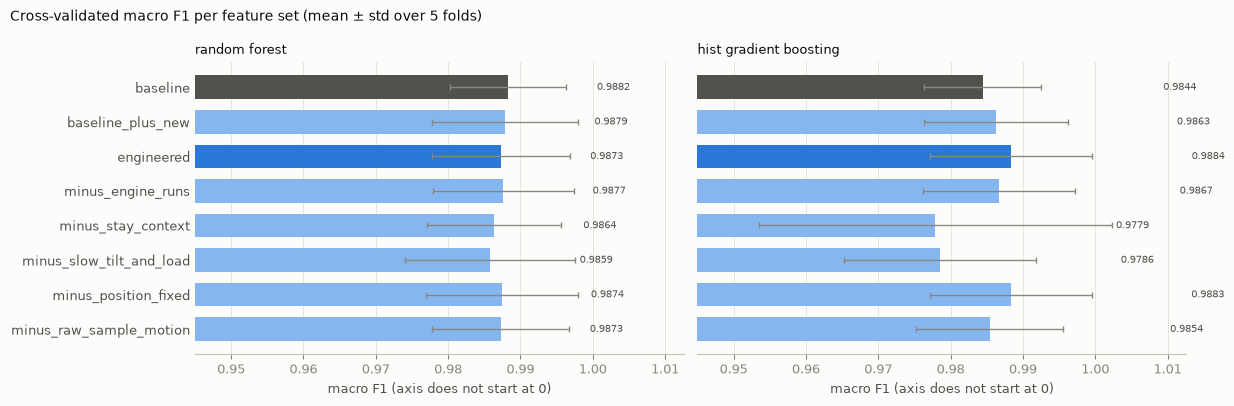

In [17]:
def set_bars(table, value, err=None, title="", xlabel="macro F1 (axis does not start at 0)"):
    # One panel per model, one bar per feature set; baseline and engineered stand out.
    models = table.index.get_level_values(0).unique()
    sets = list(SETS)
    fig, axes = plt.subplots(1, len(models), figsize=(6.2 * len(models), 0.36 * len(sets) + 1.2), sharey=True)
    lo = np.floor((table[value] - (table[err] if err else 0)).min() * 200) / 200 - 0.005
    hi = (table[value] + (table[err] if err else 0)).max()
    for ax, model_name in zip(np.atleast_1d(axes), models):
        t = table.loc[model_name].reindex(sets)
        yy = np.arange(len(sets))[::-1]
        colours = [BLUE if s == "engineered" else INK_2 if s == "baseline" else "#86b6ef" for s in sets]
        ax.barh(yy, t[value] - lo, left=lo, height=0.68, color=colours,
                xerr=t[err] if err else None, error_kw={"ecolor": MUTED, "elinewidth": 1, "capsize": 2})
        for yi, v in zip(yy, t[value]):
            ax.text(v + (t[err].max() if err else 0) + (hi - lo) * 0.01, yi, f"{v:.4f}", va="center", fontsize=7.5, color=INK_2)
        ax.set_xlim(lo, hi + (hi - lo) * 0.18)
        ax.set_yticks(yy, sets)
        ax.tick_params(axis="y", length=0)
        ax.grid(axis="x", linewidth=0.6)
        ax.set_axisbelow(True)
        ax.spines["left"].set_visible(False)
        ax.set_title(model_name.replace("_", " "), loc="left", fontsize=9.5)
        ax.set_xlabel(xlabel)
    fig.suptitle(title, x=0.01, ha="left", fontsize=10)
    plt.tight_layout()
    plt.show()


if cv_rows:
    set_bars(cv_table, "cv_macro_f1", "cv_std", "Cross-validated macro F1 per feature set (mean ± std over 5 folds)")

## 9. Test once: baseline against engineered

Fitted on all training episodes, scored once on the test episodes. `macro_f1_clean` leaves out
the test minutes next to a label edge.

In [18]:
TEST_SETS = ["baseline", "engineered"]
fitted, test_pred, rows = {}, {}, []
away = ~test["near_boundary"].to_numpy()
for model_name in MODELS:
    for set_name in TEST_SETS:
        cols = SETS[set_name]
        t0 = time.perf_counter()
        model = clone(MODELS[model_name]).fit(train[cols], y_train)
        pred = model.predict(test[cols])
        fitted[model_name, set_name], test_pred[model_name, set_name] = model, pred
        rows.append({"model": model_name, "set": set_name, "macro_f1": macro_f1_present(y_test, pred),
                     "macro_f1_clean": macro_f1_present(y_test[away], pred[away]),
                     "accuracy": accuracy_score(y_test, pred), "kappa": cohen_kappa_score(y_test, pred),
                     **dict(zip(MODES, f1_score(y_test, pred, labels=MODES, average=None, zero_division=0))),
                     "fit_s": time.perf_counter() - t0})
test_scores = pd.DataFrame(rows).set_index(["model", "set"])
test_scores.round(3)

macro_f1  macro_f1_clean  accuracy  kappa  sea_passage  manoeuvring  at_anchor  in_port  cargo_operations   fit_s
model                  set                                                                                                                          
random_forest          baseline       0.956           0.961     0.983  0.969        0.999        0.959      0.997    0.850             0.976   5.756
                       engineered     0.955           0.960     0.983  0.968        0.999        0.956      0.998    0.849             0.975   6.101
hist_gradient_boosting baseline       0.937           0.944     0.980  0.963        0.999        0.954      0.978    0.784             0.973  15.506
                       engineered     0.950           0.955     0.980  0.964        0.999        0.958      0.997    0.826             0.971  16.598

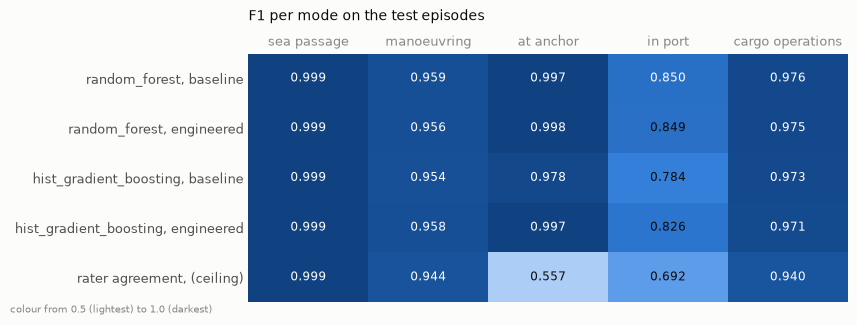

In [19]:
def f1_heatmap(table, title, vmin=0.5):
    t = table[MODES]
    fig, ax = plt.subplots(figsize=(8.6, 0.42 * len(t) + 1.1))
    ax.imshow(t.to_numpy(dtype=float), cmap=BLUES, vmin=vmin, vmax=1.0, aspect="auto")
    for i in range(t.shape[0]):
        for j in range(t.shape[1]):
            v = t.iat[i, j]
            ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=8.5,
                    color="#ffffff" if v >= vmin + 0.7 * (1 - vmin) else INK)
    ax.set_xticks(range(len(MODES)), [m.replace("_", " ") for m in MODES])
    ax.set_yticks(range(len(t)), [", ".join(map(str, n)) if isinstance(n, tuple) else n for n in t.index])
    ax.tick_params(length=0)
    ax.xaxis.tick_top()
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(title, loc="left", fontsize=10, pad=24)
    fig.text(0.01, 0.01, f"colour from {vmin} (lightest) to 1.0 (darkest)", fontsize=7.5, color=MUTED)
    plt.tight_layout()
    plt.show()


per_mode = pd.concat([test_scores[MODES], pd.DataFrame(
    [rater_f1.to_numpy()], columns=MODES, index=pd.MultiIndex.from_tuples([("rater agreement", "(ceiling)")]))])
f1_heatmap(per_mode, "F1 per mode on the test episodes")

### Where the in port / cargo operations mistakes sit

The comparison notebook found that most of Random Forest's remaining errors were labelled cargo
minutes it called `in_port`, far from any label edge, with the draught standing still: pauses in
cargo work, or idle hours the labeller kept calling cargo. The stay-context features were
written for exactly this. Same table, baseline against engineered.

In [20]:
t = test[["vessel", "episode", "timestamp", "mode"]].sort_values(["vessel", "timestamp"])
new_run = (t["mode"] != t.groupby("vessel")["mode"].shift()) | (t["timestamp"].diff() != pd.Timedelta(minutes=1))
run = new_run.cumsum()
t["min_to_edge"] = np.minimum(t.groupby(run).cumcount(), t[::-1].groupby(run[::-1]).cumcount()[::-1])
bins, names = [0, 15, 60, 180, np.inf], ["< 15 min", "15-60 min", "1-3 h", "> 3 h"]

rows = {}
for (model_name, set_name), pred in test_pred.items():
    p = pd.Series(pred, index=test.index).loc[t.index]
    for true_m, pred_m in [("cargo_operations", "in_port"), ("in_port", "cargo_operations")]:
        wrong = t[(t["mode"] == true_m) & (p == pred_m)]
        rows[(model_name, set_name, f"{true_m} → {pred_m}")] = (
            pd.cut(wrong["min_to_edge"], bins, right=False, labels=names).value_counts().reindex(names))
print("mistaken minutes by distance to the nearest labelled mode change")
pd.DataFrame(rows).T.assign(total=lambda d: d.sum(axis=1))

mistaken minutes by distance to the nearest labelled mode change


min_to_edge                                                   < 15 min  15-60 min  1-3 h  > 3 h  total
random_forest          baseline   cargo_operations → in_port        77        179    355    385    996
                                  in_port → cargo_operations        40         10      0      0     50
                       engineered cargo_operations → in_port       114        195    355    385   1049
                                  in_port → cargo_operations        23          0      0      0     23
hist_gradient_boosting baseline   cargo_operations → in_port       105        151    115      0    371
                                  in_port → cargo_operations        45        130    470    187    832
                       engineered cargo_operations → in_port       141        247    364    385   1137
                                  in_port → cargo_operations        18          2     82      0    102

## 10. Transfer to the ships nobody labelled

The readme's real test: train on Wendover and Brayton, run on Calder Trader (smaller, 5 s logger)
and Harrowgate (larger, 60 s logger). Nobody labelled those two, but
`testing/Ground Truth Reconstruction.ipynb` reconstructed what every ship was doing from the
physics, without the labels, at half-hour resolution. Every minute of all four ships is scored
against it; on the two labelled ships the training episodes are left out.

Read this with three caveats:
- **It is an inference, not the supervisors' file.** It agrees with labeller A on 97 % of the
  minutes, and its idle/cargo split is its least certain part.
- **It uses some of the same signals** as the new features (the engine switch, rudder spread,
  draught over the stay). Agreeing with it is not independent proof; the logging-interval check
  at the end of this step does not depend on it.
- It has a sixth state, `drifting` (engine off, free at sea). The models know five modes, so
  `drifting` counts as `at_anchor`, as labeller A labels it.

In [21]:
def vessel_minutes(vessel, chunk_days=60):
    """All 60 features for every minute of a vessel's data, in chunks with PAD_DAYS of context."""
    days = pd.DatetimeIndex(sorted(pd.Timestamp(p.stem) for p in (ROOT / "raw" / vessel).glob("*.parquet")))
    parts = []
    for i in range(0, len(days), chunk_days):
        core = days[i:i + chunk_days]
        m, f = block_features(vessel, pd.date_range(core[0] - pd.Timedelta(days=PAD_DAYS),
                                                    core[-1] + pd.Timedelta(days=PAD_DAYS), freq="D"))
        keep = ((f.index >= core[0]) & (f.index < core[-1] + pd.Timedelta(days=1))
                & (m["n_samples"].to_numpy() > 0))
        parts.append(f[keep])
    return pd.concat(parts)


VESSELS = ["calder-trader", "harrowgate", "wendover-trader", "brayton-trader"]
transfer = {}
if RUN_TRANSFER and RECONSTRUCTION.exists():
    recon = pd.read_csv(RECONSTRUCTION, parse_dates=["start", "end"])
    recon[["start", "end"]] = recon[["start", "end"]].astype("datetime64[ns]")
    recon["mode"] = recon["mode"].replace({"drifting": "at_anchor"})
    trained_on = (lab[lab["episode"].isin(set(train_all["episode"]))]
                  .groupby("episode").agg(vessel=("vessel", "first"), start=("start", "min"), end=("end", "max")))
    t0 = time.perf_counter()
    for v in VESSELS:
        F = vessel_minutes(v)
        F["truth"] = label_at(F.index, recon[recon["vessel"] == v], "mode")
        keep = F["truth"].notna().to_numpy(copy=True)     # writable: pandas 3 hands out read-only arrays
        for r in trained_on[trained_on["vessel"] == v].itertuples():
            keep &= ~((F.index >= r.start) & (F.index < r.end))
        F = F[keep].iloc[::TRANSFER_EVERY].copy()
        F[ALL_FEATURES] = clean_features(F[ALL_FEATURES])
        transfer[v] = F
    print(f"built in {time.perf_counter() - t0:.0f} s; hours scored per vessel and mode "
          f"(one minute in {TRANSFER_EVERY} is scored, counted here as {TRANSFER_EVERY}):")
    display(pd.DataFrame({v: (F["truth"].value_counts() * TRANSFER_EVERY / 60).reindex(MODES).round(0)
                          for v, F in transfer.items()}).rename_axis("hours per reconstructed mode"))
else:
    print("RUN_TRANSFER is False or the reconstruction is missing, step 10 skipped")

built in 21 s; hours scored per vessel and mode (one minute in 3 is scored, counted here as 3):


,calder-trader,harrowgate,wendover-trader,brayton-trader
hours per reconstructed mode,,,,
sea_passage,11184.0,11060.0,10346.0,11193.0
manoeuvring,108.0,112.0,118.0,62.0
at_anchor,384.0,576.0,403.0,186.0
in_port,391.0,370.0,381.0,188.0
cargo_operations,1038.0,988.0,1082.0,642.0


In [22]:
def run_transfer(model_name, set_name):
    def compute():
        cols = SETS[set_name]
        model = globals().get("fitted", {}).get((model_name, set_name))    # reuse step 9's fit if there is one
        if model is None:
            model = clone(MODELS[model_name]).fit(train[cols], y_train)
        out = {}
        for v, F in transfer.items():
            pred = model.predict(F[cols])
            f1 = f1_score(F["truth"], pred, labels=MODES, average=None, zero_division=0)
            out[v] = {"macro_f1": float(np.mean(f1)), **dict(zip(MODES, map(float, f1)))}
        return {"vessels": out}
    return cached("transfer", model_name, set_name, compute)

In [23]:
if transfer:
    tr_rows = []
    for model_name in MODELS:
        for set_name in SETS:
            r = run_transfer(model_name, set_name)
            tr_rows.append({"model": model_name, "set": set_name,
                            **{v: r["vessels"][v]["macro_f1"] for v in VESSELS}})
    transfer_table = pd.DataFrame(tr_rows).set_index(["model", "set"])
    print("macro F1 against the reconstruction (Calder and Harrowgate never seen; the labelled "
          "ships outside their training episodes)")
    display(transfer_table.round(4))

macro F1 against the reconstruction (Calder and Harrowgate never seen; the labelled ships outside their training episodes)


calder-trader  harrowgate  wendover-trader  brayton-trader
model                  set                                                                                 
random_forest          baseline                         0.9827      0.9778           0.9814          0.9813
                       baseline_plus_new                0.9814      0.9848           0.9864          0.9868
                       engineered                       0.9819      0.9865           0.9859          0.9864
                       minus_engine_runs                0.9816      0.9875           0.9869          0.9869
                       minus_stay_context               0.9804      0.9855           0.9861          0.9833
                       minus_slow_tilt_and_load         0.9788      0.9804           0.9845          0.9825
                       minus_position_fixed             0.9798      0.9870           0.9865          0.9865
                       minus_raw_sample_motion          0.9739      0.9845           0.9857          0.9783
hist_gradient_boosting baseline                         0.8952      0.9361           0.9653          0.9170
                       baseline_plus_new                0.9674      0.9803           0.9822          0.9609
                       engineered                       0.9284      0.9865           0.9856          0.9601
                       minus_engine_runs                0.9252      0.9865           0.9863          0.9600
                       minus_stay_context               0.9000      0.9585           0.9738          0.9402
                       minus_slow_tilt_and_load         0.9280      0.9844           0.9856          0.9576
                       minus_position_fixed             0.9283      0.9864           0.9856          0.9597
                       minus_raw_sample_motion          0.9171      0.9803           0.9854          0.9487

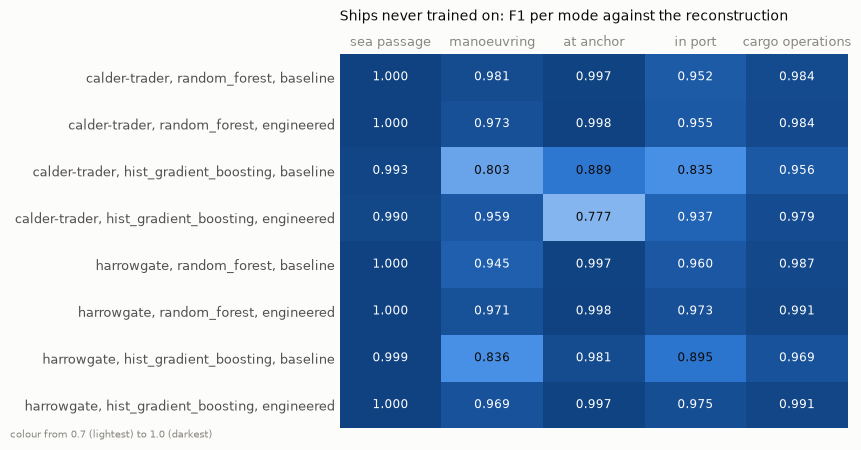

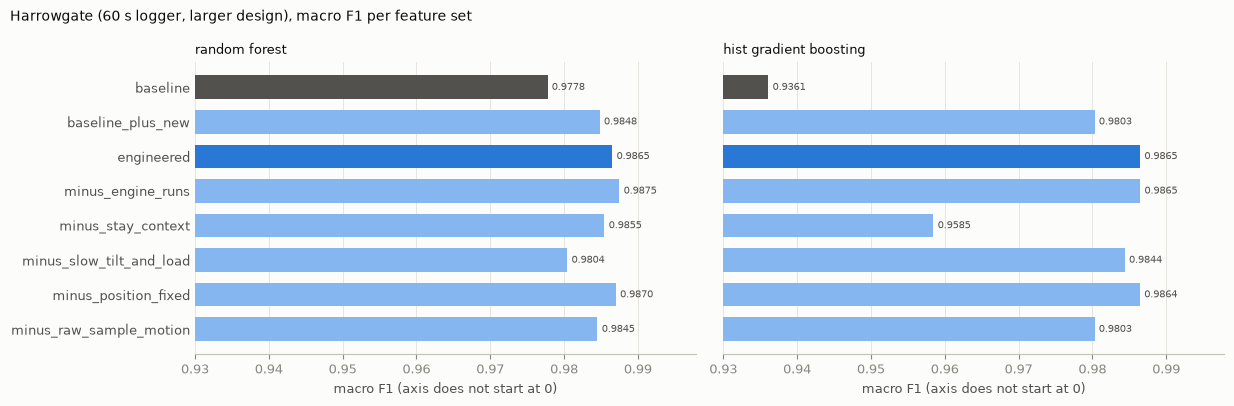

In [24]:
if transfer:
    per_mode = pd.concat({
        (v, model_name, set_name): pd.Series(run_transfer(model_name, set_name)["vessels"][v])
        for v in ["calder-trader", "harrowgate"] for model_name in MODELS for set_name in TEST_SETS
    }, axis=1).T
    f1_heatmap(per_mode, "Ships never trained on: F1 per mode against the reconstruction", vmin=0.7)
    set_bars(transfer_table[["harrowgate"]].rename(columns={"harrowgate": "f1"}), "f1",
             title="Harrowgate (60 s logger, larger design), macro F1 per feature set")

### Do the features mean the same on every logger?

This check needs no labels and no model, and does not lean on the reconstruction for anything
but grouping the minutes by mode. For each mode, how far a feature's median on Calder Trader
(5 s) and Harrowgate (60 s) sits from its median on the two labelled ships (15 s), in units of
the labelled ships' interquartile range. Around 0 the model meets familiar values on a new ship;
at 3 or more it meets values it has rarely seen in that mode. Old and new version of each
feature on neighbouring rows. A negative shift on the 5 s logger and a positive one on the
60 s logger is the logging interval, not the size of the ship.

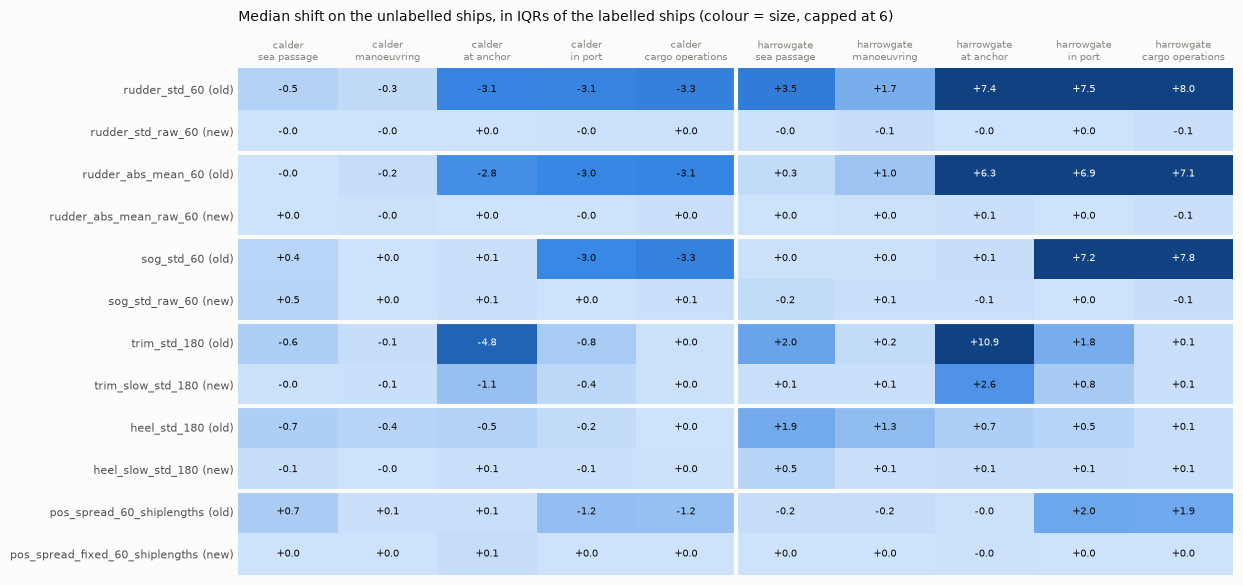

In [25]:
PAIRS = [(old, REPLACES[old]) for old in ["rudder_std_60", "rudder_abs_mean_60", "sog_std_60",
                                          "trim_std_180", "heel_std_180", "pos_spread_60_shiplengths"]]
if transfer:
    ref = pd.concat([transfer["wendover-trader"], transfer["brayton-trader"]])
    rows = {}
    for old_c, new_c in PAIRS:
        for c, kind in [(old_c, "old"), (new_c, "new")]:
            for v in ["calder-trader", "harrowgate"]:
                for mode in MODES:
                    r = ref.loc[ref["truth"] == mode, c]
                    q1, med, q3 = r.quantile([0.25, 0.5, 0.75])
                    x = transfer[v].loc[transfer[v]["truth"] == mode, c].median()
                    rows[(f"{c} ({kind})", v.split("-")[0], mode)] = (x - med) / max(q3 - q1, 1e-6)
    shift = pd.Series(rows).unstack([1, 2])
    shift = shift.reindex(index=[f"{c} ({k})" for o, n in PAIRS for c, k in [(o, "old"), (n, "new")]],
                          columns=pd.MultiIndex.from_product([["calder", "harrowgate"], MODES]))

    fig, ax = plt.subplots(figsize=(12.5, 0.36 * len(shift) + 1.6))
    ax.imshow(np.clip(shift.abs().to_numpy(float), 0, 6), cmap=BLUES, vmin=0, vmax=6, aspect="auto")
    for i in range(shift.shape[0]):
        for j in range(shift.shape[1]):
            v = shift.iat[i, j]
            ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=7.5, color="#ffffff" if abs(v) >= 4 else INK)
    ax.set_xticks(range(shift.shape[1]), [f"{v}\n{m.replace('_', ' ')}" for v, m in shift.columns], fontsize=7)
    ax.set_yticks(range(len(shift)), shift.index, fontsize=8)
    for i in range(1, len(PAIRS)):
        ax.axhline(2 * i - 0.5, color="#fcfcfb", linewidth=3)
    ax.axvline(len(MODES) - 0.5, color="#fcfcfb", linewidth=3)
    ax.tick_params(length=0)
    ax.xaxis.tick_top()
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title("Median shift on the unlabelled ships, in IQRs of the labelled ships (colour = size, capped at 6)",
                 loc="left", fontsize=10, pad=34)
    plt.tight_layout()
    plt.show()

## 11. What the engineered Random Forest relies on

Permutation importance on 20,000 test minutes, as in the comparison notebook: shuffle a whole
family of features at once and see how far macro F1 drops. The families are the comparison
notebook's, with the replaced features swapped for their new versions, plus the two new
families that have no old counterpart.

engineered random forest: macro F1 0.955 on 20,000 test rows before shuffling


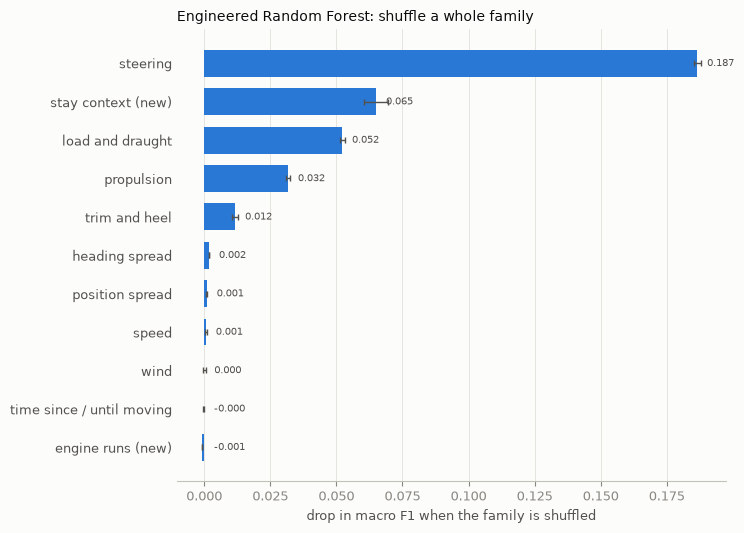

In [26]:
ENGINEERED_FAMILIES = {
    "speed": ["sog_kn", "stw_frac", "stw_minus_sog_kn", "sog_mean_15", "sog_mean_60", "stw_minus_sog_mean_60",
              "sog_std_raw_15", "sog_std_raw_60"],
    "propulsion": ["power_frac", "rpm_frac", "fuel_frac", "power_frac_mean_15", "power_frac_std_15",
                   "power_frac_mean_60", "power_frac_std_60"],
    "engine runs (new)": NEW_FAMILIES["engine_runs"],
    "steering": ["rudder_abs_deg", "rudder_std_raw_15", "rudder_std_raw_60", "rudder_abs_mean_raw_15",
                 "rudder_abs_mean_raw_60", "turn_rate_mean_15", "turn_rate_mean_60"],
    "heading spread": ["heading_circstd_60", "heading_circstd_180"],
    "position spread": NEW_FAMILIES["position_fixed"],
    "stay context (new)": NEW_FAMILIES["stay_context"],
    "load and draught": ["load_frac", "load_rate_abs_60", "load_rate_abs_180", "load_rate_abs_360"],
    "trim and heel": ["trim_slow_std_60", "trim_slow_std_180", "heel_slow_std_60", "heel_slow_std_180", "heel_abs_deg"],
    "wind": ["wind_rel_kn", "wind_rel_cos", "wind_rel_cos_mean_60"],
    "time since / until moving": ["hours_since_moving", "hours_until_moving"],
}
assert sorted(sum(ENGINEERED_FAMILIES.values(), [])) == sorted(ENGINEERED), "every feature in exactly one family"

model = fitted["random_forest", "engineered"]
sample = test.sample(n=min(20_000, len(test)), random_state=RANDOM_STATE)
Xs, ys = sample[ENGINEERED], sample["mode"]
base = macro_f1_present(ys, model.predict(Xs))
rng = np.random.default_rng(RANDOM_STATE)


def drop_when_shuffled(cols, repeats=3):
    drops = []
    for _ in range(repeats):
        Xp = Xs.copy()
        Xp[cols] = Xs[cols].to_numpy()[rng.permutation(len(Xs))]   # one shuffle for the whole family
        drops.append(base - macro_f1_present(ys, model.predict(Xp)))
    return np.mean(drops), np.std(drops)


fam = pd.DataFrame([(f, *drop_when_shuffled(cols)) for f, cols in ENGINEERED_FAMILIES.items()],
                   columns=["family", "f1_drop", "std"]).set_index("family").sort_values("f1_drop")
print(f"engineered random forest: macro F1 {base:.3f} on {len(sample):,} test rows before shuffling")

fig, ax = plt.subplots(figsize=(7.5, 0.4 * len(fam) + 1.0))
ax.barh(range(len(fam)), fam["f1_drop"], xerr=fam["std"], height=0.7, color=BLUE,
        error_kw={"ecolor": INK_2, "elinewidth": 1, "capsize": 2})
for i, v in enumerate(fam["f1_drop"]):
    ax.text(max(v, 0) + fam["f1_drop"].max() * 0.02, i, f"{v:.3f}", va="center", fontsize=7.5, color=INK_2)
ax.set_yticks(range(len(fam)), fam.index)
ax.tick_params(axis="y", length=0)
ax.grid(axis="x", linewidth=0.6)
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
ax.set_xlabel("drop in macro F1 when the family is shuffled")
ax.set_title("Engineered Random Forest: shuffle a whole family", loc="left", fontsize=10)
plt.tight_layout()
plt.show()

## 12. Save

- `data/labelled_fe.parquet`: the meta columns and the **48 engineered features**, cleaned. It is
  a drop-in for `data/labelled.parquet`: the comparison and grid-search notebooks take every
  column that is not a meta column as a feature.
- `data/labelled_fe_all.parquet`: the meta columns and all 60 (39 old, 21 new), to experiment with.
- `data/feature_engineering/feature_sets.json`: every set above, the families and what replaces what.

In [27]:
df[META + ENGINEERED].to_parquet(DATA / "labelled_fe.parquet", index=False)
df[META + ALL_FEATURES].to_parquet(DATA / "labelled_fe_all.parquet", index=False)
json.dump({"sets": SETS, "new_families": NEW_FAMILIES, "replaces": REPLACES,
           "engineered_families": ENGINEERED_FAMILIES},
          open(CACHE / "feature_sets.json", "w"), indent=1)
print(f"wrote {DATA / 'labelled_fe.parquet'} ({len(df):,} rows, {len(ENGINEERED)} features), "
      f"{DATA / 'labelled_fe_all.parquet'} and {CACHE / 'feature_sets.json'}")

wrote data/labelled_fe.parquet (162,470 rows, 48 features), data/labelled_fe_all.parquet and data/feature_engineering/feature_sets.json


**Using it in `model_comparison_lstm.ipynb` or `grid_search.ipynb`:** change the load line to
`pd.read_parquet(DATA / "labelled_fe.parquet")`. Everything runs as before, except the comparison
notebook's step 10, whose `FAMILIES` lists the old features. Replace it with:

```python
FAMILIES = json.load(open("data/feature_engineering/feature_sets.json"))["engineered_families"]
```

`show_range` in the dataset notebook builds features with its own `features()`, so a model
trained on the engineered set needs `block_features` from this notebook there.

## What to look for when you run it

Measured while building this notebook (25 Oct 2026, default settings, scikit-learn 1.7). Your
run prints its own numbers; quote those. The test episodes were not looked at while choosing
the features, so step 9 is their first use.

- **On the labelled ships, old and new features tie in cross-validation**: Random Forest about
  0.987 with either, HGB about 0.985. The labels leave little to win there: labeller A and B
  agree on in_port with an F1 of 0.69, and most remaining errors sit at label edges.
- **On the ships nobody labelled, the new features help, HGB most.** Against the reconstruction,
  HGB went from 0.95 to 0.98 macro F1 on Calder Trader and from 0.93 to 0.98 on Harrowgate.
  Random Forest went from 0.978 to about 0.988 on Harrowgate and stayed level on Calder (0.983
  against about 0.982). These HGB figures are from the 10-minute version of the trim and heel
  spread; the 30-minute version was checked with Random Forest only.
- **Stay context carries most of the gain, raw-sample motion comes second.** Without raw-sample
  motion, HGB's manoeuvring F1 on Harrowgate fell from 0.965 to 0.875: rudder spread is the
  manoeuvring signal, and the old one reads differently on a 60 s logger. Engine runs and the
  fixed position spread changed little. Engine runs are kept for about +0.002 in HGB
  cross-validation, and the position fix because the old value is numerically unstable.
- **The logging-interval check** (end of step 10): alongside, the minute-mean rudder and speed
  spreads sat about 3 IQR low on the 5 s logger and 7 to 8 high on the 60 s logger; their
  raw-sample replacements sat within half an IQR, mostly at 0. The trim spread at anchor still
  shifts (about 1 IQR low, 2.6 high), less than before.
- **Worth a look in step 9**: whether the stay-context features move the labelled cargo minutes
  that Random Forest called in_port in wendover-trader-09 and -10 (the comparison notebook's
  step 6). If they do, the model has learned the labellers' habit of running a cargo block on
  through a pause; check against the reconstruction before calling that an improvement.